In [1]:
import pandas as pd

In [3]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles/folders here:")
print(os.listdir())

Current folder:
d:\CN_AI_DWM\notebooks

Files/folders here:
['01_data_exploration.ipynb']


In [4]:
df = pd.read_csv("../data/raw/sentinelnet_sample_500.csv")

In [5]:
df.head()

,session_id,device_id,timestamp,requests_per_sec,session_duration,packet_size_mean,packet_size_var,request_interval_mean,request_interval_var,bytes_transferred,num_connections,protocol,label,bot_tier
0,S0001,PC09,03-08-2026 07:44,0.674,144.392,928.925,380399.575,1.4826,0.5823,93031,17,TCP,Suspicious,NaN
1,S0002,PC14,12-08-2026 19:33,0.933,89.408,666.445,46593.817,1.0718,0.8471,59414,11,TCP,Human,NaN
2,S0003,PC12,05-08-2026 04:02,0.461,76.377,639.805,52824.270,2.1674,7.0056,18604,13,TCP,Suspicious,NaN
3,S0004,PC13,05-08-2026 18:58,2.001,99.808,389.192,84865.353,0.4997,0.3648,82842,8,TCP,Human,NaN
4,S0005,PC07,04-08-2026 19:37,1.671,66.736,613.377,125751.361,0.5983,0.1995,53865,2,TCP,Human,NaN


In [6]:
df.shape

(500, 14)

In [7]:
df.columns

Index(['session_id', 'device_id', 'timestamp', 'requests_per_sec',
       'session_duration', 'packet_size_mean', 'packet_size_var',
       'request_interval_mean', 'request_interval_var', 'bytes_transferred',
       'num_connections', 'protocol', 'label', 'bot_tier'],
      dtype='str')

In [8]:
df["label"].value_counts()

label
Human         200
Bot           200
Suspicious    100
Name: count, dtype: int64

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   session_id             500 non-null    str    
 1   device_id              500 non-null    str    
 2   timestamp              500 non-null    str    
 3   requests_per_sec       500 non-null    float64
 4   session_duration       500 non-null    float64
 5   packet_size_mean       500 non-null    float64
 6   packet_size_var        500 non-null    float64
 7   request_interval_mean  500 non-null    float64
 8   request_interval_var   500 non-null    float64
 9   bytes_transferred      500 non-null    int64  
 10  num_connections        500 non-null    int64  
 11  protocol               500 non-null    str    
 12  label                  500 non-null    str    
 13  bot_tier               200 non-null    str    
dtypes: float64(6), int64(2), str(6)
memory usage: 54.8 KB


In [10]:
df.isnull().sum()

session_id                 0
device_id                  0
timestamp                  0
requests_per_sec           0
session_duration           0
packet_size_mean           0
packet_size_var            0
request_interval_mean      0
request_interval_var       0
bytes_transferred          0
num_connections            0
protocol                   0
label                      0
bot_tier                 300
dtype: int64

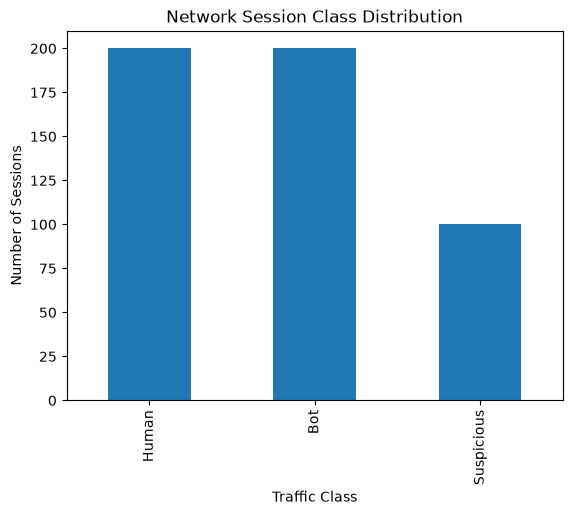

In [12]:
import matplotlib.pyplot as plt

df["label"].value_counts().plot(kind="bar")

plt.title("Network Session Class Distribution")
plt.xlabel("Traffic Class")
plt.ylabel("Number of Sessions")
plt.show()

In [13]:
df.describe()

,requests_per_sec,session_duration,packet_size_mean,packet_size_var,request_interval_mean,request_interval_var,bytes_transferred,num_connections
count,500.000000,500.000000,500.000000,5.000000e+02,500.000000,500.000000,5.000000e+02,500.000000
mean,3.264990,84.684342,676.561462,1.531867e+05,0.561364,0.593138,1.814360e+05,9.400000
std,2.388188,72.387966,228.050381,2.080395e+05,0.519757,1.701360,4.283207e+05,3.972854
min,0.238000,7.701000,80.000000,2.009859e+03,0.066700,0.000100,4.374000e+03,2.000000
25%,1.300750,40.398000,541.488250,3.413394e+04,0.206175,0.008800,5.795100e+04,6.000000
50%,2.635500,63.098000,658.041000,8.099076e+04,0.379450,0.097300,1.040805e+05,9.000000
75%,4.851000,105.907750,804.734000,1.769536e+05,0.768725,0.519250,1.808578e+05,12.000000
max,15.000000,643.167000,1500.000000,1.500000e+06,4.201000,24.905800,7.337225e+06,22.000000


In [ ]:
# Feature Distributions by Class
import seaborn as sns
import matplotlib.pyplot as plt

num_cols = df.select_dtypes(include=["float64", "int64"]).columns
for col in num_cols:
    plt.figure(figsize=(6, 4))
    sns.histplot(data=df, x=col, hue="label", kde=True, bins=30)
    plt.title(f"Distribution of {col} by Class")
    plt.show()


In [ ]:
# Boxplots for Features vs Label
for col in num_cols:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df, x="label", y=col)
    plt.title(f"{col} vs Label")
    plt.show()


In [ ]:
# Correlation Matrix (Numerical Features Only)
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix of Numerical Features")
plt.show()


In [ ]:
# Class-wise Statistics
class_stats = df.groupby("label")[num_cols].mean()
print("Mean values of numerical features by class:")
display(class_stats)
